<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">📘 Batch, micro-batch a streaming - Northwind </h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">V nadväznosti na Seminár 8 - Zadanie 1a s MovieLens spracujeme údaje o objednávkach. Tentoraz si jednotlivé kroky naprogramujete samostatne od načítania CSV po porovnanie výsledkov.</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z kurzu si stiahnite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> (stĺpce <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">customerid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">employeeid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid</code>). Súbor uložte do rovnakého priečinka ako notebook. Knižnice a PostgreSQL už máte pripravené.</p>

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 1 – Načítanie a časová distribúcia objednávok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Načítajte súbor <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> a zmeňte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> na dátum. Zistite časový rozsah a počet objednávok podľa roku a mesiaca. Rozloženie zobrazte v grafe.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">pd.read_csv(..., parse_dates=["orderdate"])</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.year</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.to_period("M")</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">value_counts()</code>.</div>

Počet objednavok: 196
Najstarsia: 1996-07-04 00:00:00
Najnovsia: 1997-02-12 00:00:00


,orderid,customerid,employeeid,orderdate,shipperid
0,10248,90,5,1996-07-04,3
1,10249,81,6,1996-07-05,1
2,10250,34,4,1996-07-08,2
3,10251,84,3,1996-07-08,1
4,10252,76,4,1996-07-09,2


orderdate
1996    152
1997     44
Name: count, dtype: int64

orderdate
1996-07    22
1996-08    25
1996-09    23
1996-10    26
1996-11    25
1996-12    31
1997-01    33
1997-02    11
Freq: M, Name: count, dtype: int64

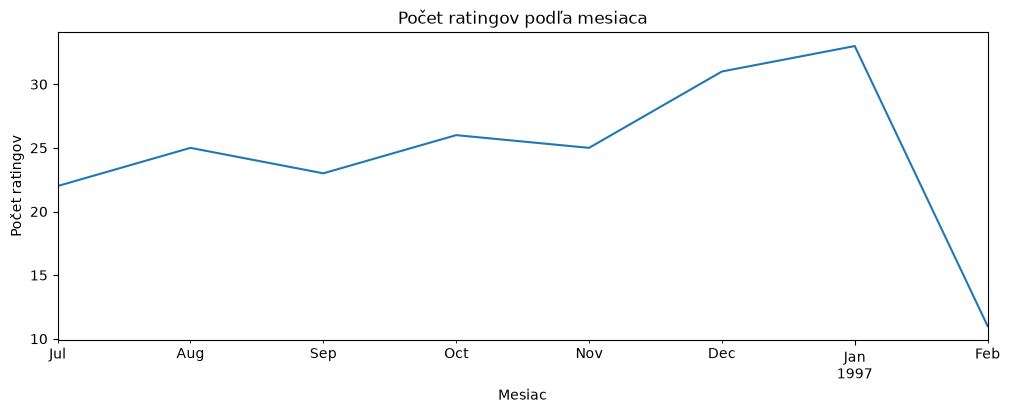

In [6]:
# Vaše riešenie
from pathlib import Path
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = Path(r"D:\Downloads\orders.csv")

if not CSV_PATH.is_file():
    raise FileNotFoundError(f"CSV sa nenašlo: {CSV_PATH}. Upravte CSV_PATH.")


ratings = pd.read_csv(CSV_PATH, parse_dates=["orderdate"])

required = {"orderid", "customerid", "employeeid", "orderdate", "shipperid"}
missing = required - set(ratings.columns)
if missing:
    raise ValueError(f"V CSV chýbajú stĺpce: {sorted(missing)}")

print("Počet objednavok:", len(ratings))
print("Najstarsia:", ratings["orderdate"].min())
print("Najnovsia:", ratings["orderdate"].max())
display(ratings.head())

ratings_by_year = (
    ratings["orderdate"]
    .dt.year
    .value_counts()
    .sort_index()
)
display(ratings_by_year)

# distribúcia podľa mesiaca
ratings_by_month = (
    ratings["orderdate"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)
display(ratings_by_month.head(15))
# vizualizácia mesačnej aktivity
ratings_by_month.plot(
    figsize=(12, 4),
    title="Počet ratingov podľa mesiaca"
)
plt.xlabel("Mesiac")
plt.ylabel("Počet ratingov")
plt.show()


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 2 – Historické a novšie objednávky</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Podľa časového rozloženia zvoľte <strong>hranice 1. januára 1997</strong>. Staršie objednávky budú historický batch, objednávky od tohto dátumu využijeme na simuláciu príchodu udalostí.</p>
<ul style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.7; margin-top: 6px; padding-left: 24px;"><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">historical_orders</code> budú objednávky pred hranicou,</li><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">new_orders</code> naopak objednávky od hranice (vrátane),</li><li style="margin-bottom: 5px;">overte, že obe skupiny spolu obsahujú všetky objednávky.</li></ul>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong>Upozornenie: </strong> „Novšie“ objednávky sú stále <strong>historické záznamy</strong>. V nasledujúcich úlohách budeme ich príchod len simulovať.</div>

In [ ]:
# Vaše riešenie


Historické objednávky: 152
Novšie objednávky: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 3 – Raw ingestion do PostgreSQL</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte databázu <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">Northwind</code>, tabuľku <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> s primárnym kľúčom <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code> a nahrajte všetky záznamy z CSV. Predpokladáme, že PostgreSQL a balíky už fungujú inštaláciu ani test verzie preto nemusíte riešiť.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> najskôr sa pripojte do databázy <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">postgres</code>, vytvorte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders_practice</code> s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">AUTOCOMMIT</code>, potom zmeňte pripojenie. Na opakovateľný import použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">DROP TABLE IF EXISTS</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">to_sql(..., if_exists="append", index=False)</code>.</div>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong> Upozornenie:</strong> Pri opakovanom spustení sa obsah tabuľky <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> vymaže a znovu nahrá. Nepoužívajte názov databázy, ktorá už obsahuje vaše vlastné dáta.</div>

In [ ]:
# Vaše riešenie


Tabuľka orders bola vytvorená a naplnená.


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 4 – Batch processing</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z historických objednávok vypočítajte <strong>počet objednávok</strong>, <strong>počet zákazníkov</strong> a <strong>percento objednávok s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid = 3</code></strong>. Výsledok získame jednorazovo za celú historickú skupinu.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Percento vypočítate ako <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(počet objednávok dopravcu 3 / počet všetkých objednávok) * 100</code>. Výraz <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(df["shipperid"] == 3).sum()</code> spočíta vyhovujúce riadky.</div>

In [ ]:
# Vaše riešenie


Objednávok: 152
Zákazníkov: 66
Dopravca 3 (%): 38.16


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 5 – Spoločná vzorka pre tri prístupy</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na porovnanie musí každý prístup dostať <strong>rovnaké objednávky v rovnakom poradí</strong>. Z PostgreSQL vyberte novšie objednávky a zoraďte ich podľa <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">text()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">engine.connect()</code> a pomenované parametre SQL <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:cutoff</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:limit</code>. V tomto datasete je po hranici 44 objednávok, preto postačuje <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">SAMPLE_SIZE = 44</code>.</div>

In [ ]:
# Vaše riešenie


Objednávok v simulácii: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 6 – Simulácia micro-batchingu a streamingu</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Historické objednávky budeme prehrávať postupne. <strong>Streaming</strong> aktualizuje podiel dopravcu 3 po každej objednávke, <strong>micro-batch</strong> po uzavretí krátkeho časového okna. Batch poskytne výsledok až po príchode celej vzorky.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Pre tento malý dataset nastavíme <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">EVENT_DELAY_SEC = 0.04</code> (40 ms medzi objednávkami) a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">MICRO_WINDOW_SEC = 0.30</code> (približne 300 ms na dávku). Skutočné časy závisia od výkonu počítača.</div>

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok A – Nastavenia a priebežný stav</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Pripravte časové parametre, počítadlá a zoznamy na zaznamenávanie priebežných výsledkov. Pri micro-batchingu potrebujeme navyše premenné pre neuzavretú dávku.</p>

In [ ]:
# Vaše riešenie


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok B – Spracovanie udalostí</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Prejdite objednávky postupne. Pri streamingu priebežne zapisujte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(čas, počet, percento)</code>. Pri micro-batchingu spracujte nazbierané objednávky až po uplynutí okna.</p>

In [ ]:
# Vaše riešenie


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok C – Posledná dávka a batch</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Nezabudnite spracovať poslednú nedokončenú micro-batch dávku. Nakoniec vypočítajte jednorazový batch výsledok pre tú istú vzorku a overte rovnosť výsledných percent.</p>

In [ ]:
# Vaše riešenie


Počet objednávok: 44
Batch (%): 22.73
Micro-batch (%): 22.73
Streaming (%): 22.73


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 7 – Grafy priebežných výsledkov</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte <strong>tri samostatné grafy</strong> pod sebou. V prvom zobrazte jednorazový batch bod, v druhom schodovitý priebeh micro-batchingu a v treťom streamingovú krivku. Použite spoločné osi, aby boli percentá porovnateľné.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plt.subplots(3, 1, sharex=True, sharey=True)</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">scatter()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">step(where="post")</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plot()</code>.</div>

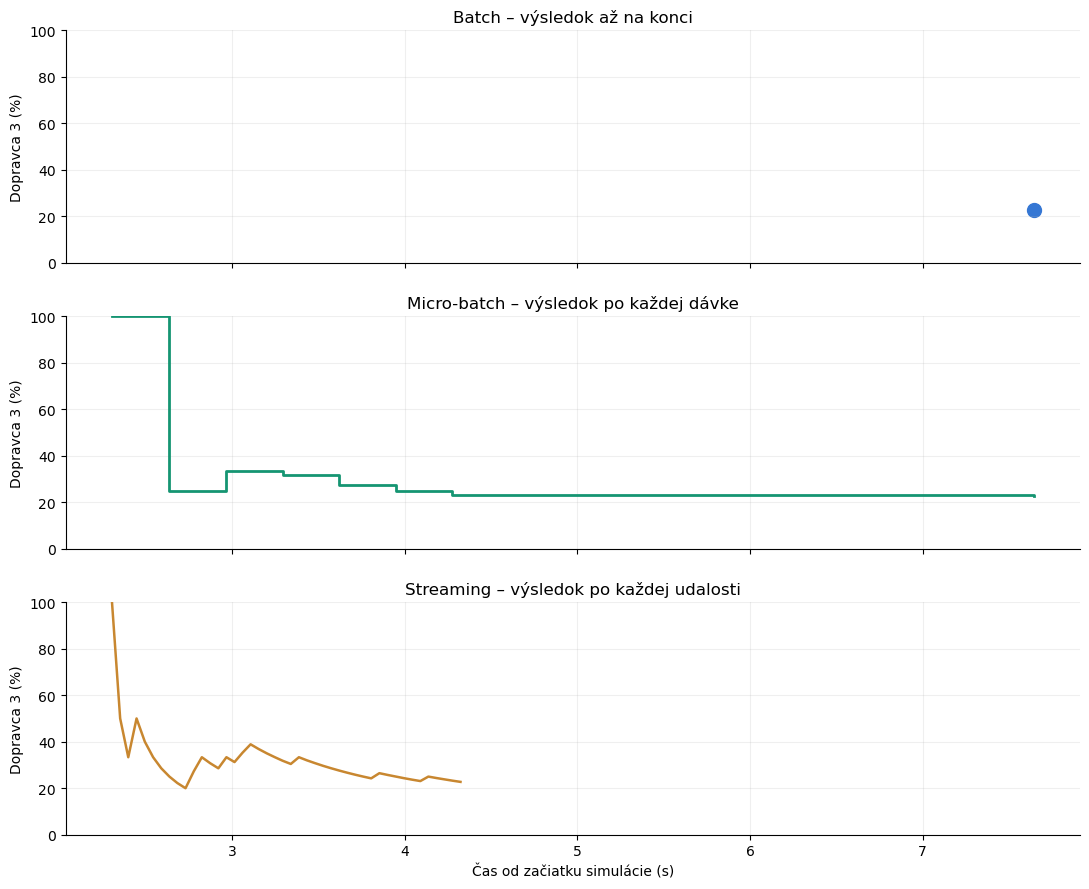

In [ ]:
# Vaše riešenie


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 8 – Frekvencia aktualizácií a prvý výsledok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na troch grafoch znázornite, koľkokrát sa priebežný výsledok aktualizoval. Potom vytvorte jednoduchú tabuľku, ktorá porovná <strong>čas prvého výsledku</strong>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Pri počte aktualizácií nie je vhodné zdieľať os Y: batch má jeden výsledok, streaming jeden po každej udalosti. Os X zdieľajte.</div>

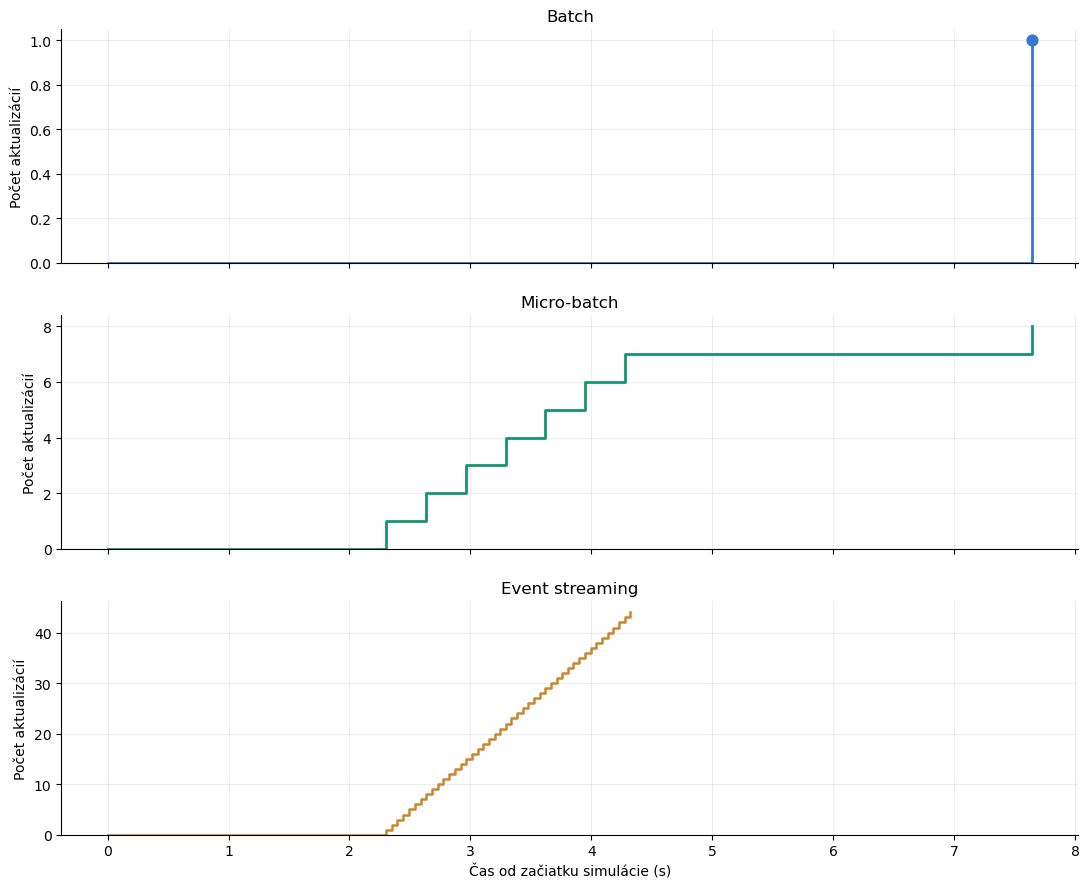

        Prístup Prvý výsledok (s)
          Batch             7.645
    Micro-batch             2.303
Event streaming             2.303


In [ ]:
# Vaše riešenie


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">
  📘 Kontrola Git repozitára po 8. týždni
</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Po dokončení všetkých úloh z 8. týždňa skontrolujte, či máte vo svojom Git
  repozitári vytvorenú samostatnú vetvu
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  a či sa v nej nachádza vypracovaný notebook vytvorený počas cvičenia.
</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Obsah vetvy
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  by mal mať približne nasledujúcu štruktúru:
</p>
<pre style="background: #f9fafb; color: #111827; padding: 14px; border-radius: 7px; overflow: auto; font-size: 13px; line-height: 1.7; font-family: ui-monospace, SFMono-Regular, Menlo, monospace;">week-08
│
├── ratings.csv
├── orders.csv
│
├── batch_streaming.ipynb
└── batch_streaming_orders.ipynb
</pre>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #eab308; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">
  ⚠️ <strong>Kontrola GitHubu:</strong> Skontrolujte, či sa všetky uvedené súbory
  nachádzajú aj vo vzdialenom repozitári na GitHube. Ak ich vidíte iba lokálne
  vo VS Code, zmeny ešte neboli úspešne odoslané pomocou
  <strong>commit</strong> a <strong>push</strong>.
</div>